# Phần 3. Làm sạch dữ liệu Olist

Phần này làm sạch dữ liệu nguồn dựa trên các phát hiện của Phần 2 để tạo bảng mà mỗi dòng là một sản phẩm trong một đơn hàng. Mỗi quy tắc xử lý mang một trong hai nhãn: Bắt buộc (giá trị không hợp lệ theo miền đã xác định) hoặc Quyết định (nhóm chọn một trong các cách xử lý khả dĩ), kèm lý do, số dòng bị ảnh hưởng và ghi rõ có xem freight_value hay không.

### 1. Chuẩn bị và nhắc lại phát hiện của Phần 2

#### 1.1 Nạp thư viện và dữ liệu

Nạp thư viện, mount Google Drive, đọc 7 tệp CSV và in kích thước từng bảng.

In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

from google.colab import drive
drive.mount('/content/drive/')

raw = '/content/drive/MyDrive/Colab Notebooks/'

orders    = pd.read_csv(raw + 'olist_orders_dataset.csv')
items     = pd.read_csv(raw + 'olist_order_items_dataset.csv')
products  = pd.read_csv(raw + 'olist_products_dataset.csv')
customers = pd.read_csv(raw + 'olist_customers_dataset.csv')
geo       = pd.read_csv(raw + 'olist_geolocation_dataset.csv')
sellers   = pd.read_csv(raw + 'olist_sellers_dataset.csv')
cat_map   = pd.read_csv(raw + 'product_category_name_translation.csv')

tables = {
    'orders': orders, 'items': items, 'products': products, 'customers': customers,
    'geo': geo, 'sellers': sellers, 'cat_map': cat_map,
}

for name, t in tables.items():
    print(f'{name:<10}: {t.shape}')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).
orders    : (99441, 8)
items     : (112650, 7)
products  : (32951, 9)
customers : (99441, 5)
geo       : (1000163, 5)
sellers   : (3095, 4)
cat_map   : (71, 2)


Khai báo hàm step() (loại dòng và ghi vào nhật ký), ghi_thay_doi() (ghi bước sửa giá trị) và haversine_km() (khoảng cách giữa hai tọa độ, đơn vị km).

In [117]:
audit_rows = []
change_rows = []

def step(frame, keep, section, rule, loai, co_xem_freight):
    truoc = len(frame)
    out = frame[keep].copy()
    audit_rows.append({
        'muc': section, 'quy_tac': rule, 'loai_quy_tac': loai, 'co_xem_freight': co_xem_freight,
        'truoc': truoc, 'sau': len(out), 'so_dong_loai': truoc - len(out),
    })
    print(f'{section:<8} {rule:<42} {truoc:>7} -> {len(out):>7} (loai {truoc - len(out)})')
    return out

def ghi_thay_doi(section, rule, so_dong, loai, co_xem_freight):
    change_rows.append({
        'muc': section, 'quy_tac': rule, 'loai_quy_tac': loai,
        'co_xem_freight': co_xem_freight, 'so_dong_anh_huong': so_dong,
    })
    print(f'{section:<8} {rule:<42} anh huong {so_dong} dong')

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

#### 1.2 Các phát hiện của Phần 2

Bảng sau nhắc lại các phát hiện của Phần 2 liên quan đến dữ liệu được làm sạch ở Phần 3. Payments và reviews được đánh giá là không dùng làm đặc trưng (mục 2.9) nên không được nạp ở Phần 3.

| STT | Mục | Loại phát hiện | Bảng/cột | Số liệu ghi nhận | Ý nghĩa/giới hạn |
|---:|---|---|---|---|---|
| 1 | 2.2 | Kiểu dữ liệu | orders (5 cột ngày), items.shipping_limit_date, reviews (2 cột ngày) | 8 cột ngày ở kiểu chữ | Cần chuyển kiểu nếu một quy trình sau này cần tính toán thời gian; notebook này không chuyển kiểu |
| 2 | 2.3 | Thiếu dữ liệu | orders.order_approved_at | 160 dòng thiếu | Độ đầy đủ của mốc duyệt đơn bị hạn chế |
| 3 | 2.3 | Thiếu dữ liệu | orders.order_delivered_carrier_date | 1,783 dòng thiếu | Độ đầy đủ của mốc giao cho vận chuyển bị hạn chế |
| 4 | 2.3 | Thiếu dữ liệu | orders.order_delivered_customer_date | 2,965 dòng thiếu | Độ đầy đủ của mốc giao khách bị hạn chế |
| 5 | 2.3 | Thiếu dữ liệu | products: danh mục và ba trường mô tả | 610 ô thiếu ở mỗi trường | Là số ô thiếu theo từng trường, chưa tính riêng số sản phẩm bị ảnh hưởng |
| 6 | 2.3 | Thiếu dữ liệu | products: cân nặng và ba kích thước | 2 ô thiếu ở mỗi trường | Thiếu thông tin vật lý có thể ảnh hưởng nếu dùng các trường này |
| 7 | 2.3 | Dòng trùng hoàn toàn | geo | 261,831 dòng theo thống kê ghi nhận | Trùng hoàn toàn không giống vấn đề nhiều tọa độ trên cùng mã bưu chính |
| 8 | 2.4 | Giá trị cần điều tra, không tự động sai miền | items.freight_value | 383 dòng bằng 0 theo thống kê ghi nhận | Không âm nên không vi phạm điều kiện miền đã đặt ra; nguyên nhân chưa xác định |
| 9 | 2.4 | Sai miền theo quy tắc đã đặt | products.product_weight_g | 4 sản phẩm có cân nặng bằng 0 theo thống kê ghi nhận | Cần phân biệt với giá trị thiếu; chưa chỉnh sửa tại phần EDA |
| 10 | 2.4 | Điểm cần rà soát | geo tọa độ | 31 điểm ngoài khung bao Brazil theo thống kê ghi nhận | Khung bao là kiểm tra sàng lọc, không đủ để xác nhận chắc chắn dữ liệu sai |
| 11 | 2.5 | Khóa không duy nhất | geo.geolocation_zip_code_prefix | 1,000,163 dòng cho 19,015 mã | Ghép trực tiếp có thể làm nhân bản dòng quan sát |
| 12 | 2.6 | Khóa tham chiếu không khớp | products.product_category_name so với cat_map | 13 sản phẩm theo thống kê ghi nhận, không tính danh mục thiếu | Không có bản dịch cho một số mã danh mục |
| 13 | 2.6 | Mã bưu chính không được phủ | Khách hàng so với geo | 278 dòng theo thống kê ghi nhận | Không tìm thấy mã bưu chính trong bảng tọa độ |
| 14 | 2.6 | Mã bưu chính không được phủ | Người bán so với geo | 7 người bán theo thống kê ghi nhận | Không tìm thấy mã bưu chính trong bảng tọa độ |
| 15 | 2.7 | Độ phủ thời gian không đồng đều | orders.order_purchase_timestamp | 2016 chỉ có vài tháng với lượng đơn thấp; cuối 2018 cũng ít đơn | Mô tả độ phủ, không đủ kết luận timeliness hoặc nguyên nhân |
| 16 | 2.8 | Giá trị vượt rào IQR | items.price, items.freight_value, products cân nặng/kích thước | 7.48%; 10.31%; 13.81%; 4.19%; 5.74%; 2.77% theo thống kê ghi nhận | Là dấu hiệu phân phối cần xem xét, không phải tỷ lệ dữ liệu sai hay phép đo Accuracy |
| 17 | 2.9 | Nguy cơ rò rỉ dữ liệu | payments.payment_value | 99.42% trong 98,665 đơn khớp tổng price + freight_value theo thống kê ghi nhận | Bằng chứng thực nghiệm về nguy cơ; không khẳng định quan hệ đúng tuyệt đối cho mọi đơn |

### 1.3. Nguyên tắc làm sạch dữ liệu

Quá trình làm sạch dữ liệu tuân theo hai nguyên tắc: **ngăn ngừa rò rỉ dữ liệu** và **ghi nhận đầy đủ quá trình xử lý**.

#### 1.3.1. Ngăn ngừa rò rỉ dữ liệu (Data Leakage)

Kaufman và cộng sự (2012) nghiên cứu hiện tượng rò rỉ dữ liệu và các phương pháp phòng tránh [1]. Rò rỉ dữ liệu xảy ra khi thông tin không phù hợp hoặc không có sẵn tại thời điểm dự đoán được sử dụng trong quá trình xây dựng mô hình, khiến kết quả đánh giá có thể sai lệch.

Vì vậy, dự án chỉ thực hiện các bước làm sạch dựa trên quy tắc xác định trước, như kiểm tra giá trị thiếu và giá trị ngoài miền hợp lệ. Những ngưỡng phụ thuộc vào phân phối dữ liệu được xác định trên tập huấn luyện, tránh sử dụng thông tin từ tập kiểm tra.

#### 1.3.2. Ghi nhận quá trình xử lý (Audit Trail)

NIST đề cập đến *audit trail* trong SP 800-53 Rev. 5 như một cơ chế ghi lại hoạt động để phục vụ kiểm tra và truy vết [2].

Dựa trên nguyên tắc này, dự án ghi nhận số dòng trước và sau mỗi bước làm sạch. Mục 8 tổng hợp các số liệu để đối chiếu lượng dữ liệu thay đổi trong toàn bộ quá trình.


### 2. Chuẩn bị các bảng trước khi ghép

**Mục đích:**
- Đảm bảo khóa ghép geolocation_zip_code_prefix của bảng geo là duy nhất.
- Xử lý 13 sản phẩm có danh mục không xuất hiện trong bảng cat_map.

**Nguyên nhân cần xử lý trước khi ghép:**

- **Bảng geo:** Khóa geolocation_zip_code_prefix không duy nhất; bảng có 261.831 dòng trùng hoàn toàn. Nếu ghép trực tiếp, một dòng của bảng chính có thể khớp với nhiều dòng trong geo, làm tăng số dòng sau ghép và khiến các giá trị như freight_value bị tính lặp trong thống kê.

- **Bảng cat_map:** Có 13 sản phẩm mang mã danh mục không tìm thấy trong bảng ánh xạ `cat_map`. Cần xử lý các mã danh mục này để xác định cách ánh xạ trước khi ghép, tránh phát sinh giá trị danh mục bị thiếu do không có khóa khớp.

- **Tọa độ địa lý thiếu:** Được xử lý sau khi ghép để tận dụng thông tin bổ sung từ các bảng liên quan.

#### 2.1 Xử lý tọa độ của mã bưu chính

**Nguyên nhân:**

- geo có 31 điểm có tọa độ ngoài khung bao Brazil (2.4 của Phần 2).
- Mã bưu chính có nhiều dòng trong geo (2.5 của Phần 2), nên cần một tọa độ đại diện cho mỗi mã.


**Phần 1:** Kiểm tra các điểm nằm ngoài khung bao của Brazil. Vẽ điểm trong khung (xám), điểm ngoài khung (xanh) và khung bao (đỏ).

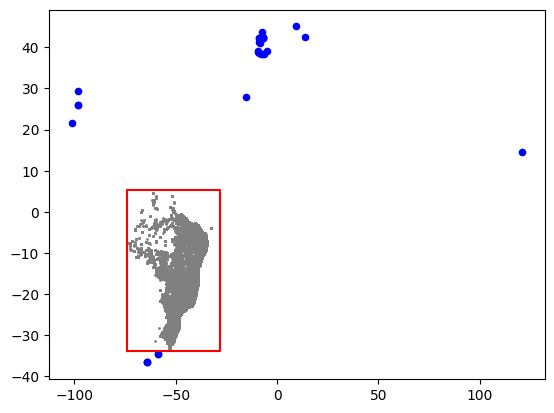

31 1000132 19011


In [118]:
trong_khung = geo['geolocation_lat'].between(-34, 5.3) & geo['geolocation_lng'].between(-74, -28)
geo_in = geo[trong_khung]
geo_out = geo[~trong_khung]

plt.scatter(geo_in['geolocation_lng'], geo_in['geolocation_lat'], s=1, c='gray')
plt.scatter(geo_out['geolocation_lng'], geo_out['geolocation_lat'], s=20, c='blue')
plt.plot([-74, -28, -28, -74, -74], [-33.8, -33.8, 5.3, 5.3, -33.8], c='red')
plt.show()
print(len(geo_out), len(geo_in), geo_in['geolocation_zip_code_prefix'].nunique())

**Kết luận:** loại 31 điểm, geo_in còn 1,000,132 dòng và 19,011 mã

**Loại quy tắc:** Bắt buộc, không xem freight_value.

**Lý do:** các điểm này đều ghi mã bang hợp lệ (2.4 của Phần 2) nhưng tọa độ nằm ngoài khung bao, trong khi khung bao chứa toàn bộ lãnh thổ Brazil, nên hai thông tin mâu thuẫn và tọa độ không dùng được để tính khoảng cách.

**Hạn chế:** điểm sai nằm trong khung bao không bị loại ở bước này.


In [119]:
geo_in = geo[trong_khung]
print('so dong geo    :', len(geo), '->', len(geo_in))
print('so ma buu chinh: ', geo['geolocation_zip_code_prefix'].nunique(), '->', geo_in['geolocation_zip_code_prefix'].nunique())

so dong geo    : 1000163 -> 1000132
so ma buu chinh:  19015 -> 19011


**Phần 2:** đo sai số khi mỗi mã bưu chính được đại diện bằng một toạ độ, với hai cách chọn: trung vị và trung bình toạ độ của các điểm thuộc mã đó.

**Lý do kiểm tra:** gộp nhiều điểm về một toạ độ làm toạ độ khác vị trí của từng điểm; khoảng cách từ mỗi điểm đến toạ độ đại diện cho biết mức sai này.


 In thống kê mô tả sai số của cả hai cách

         trung_vi  trung_binh
count  1000132.00  1000132.00
mean         1.27        1.48
std         18.37       16.96
min          0.00        0.00
25%          0.26        0.31
50%          0.50        0.57
75%          0.89        1.02
max       3360.80     2993.57


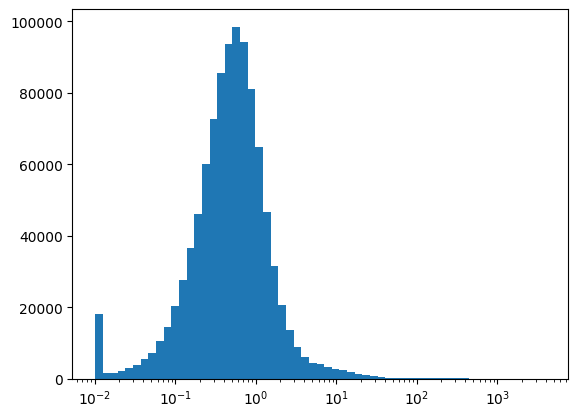

In [120]:
tv = geo_in.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].transform('median')
sai_so = haversine_km(geo_in['geolocation_lat'], geo_in['geolocation_lng'], tv['geolocation_lat'], tv['geolocation_lng'])
tb = geo_in.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].transform('mean')
sai_tb = haversine_km(geo_in['geolocation_lat'], geo_in['geolocation_lng'], tb['geolocation_lat'], tb['geolocation_lng'])
print(pd.DataFrame({'trung_vi': sai_so.describe(), 'trung_binh': sai_tb.describe()}).round(2))

plt.hist(sai_so.clip(lower=0.01), bins=np.logspace(-2, 3.6, 60))
plt.xscale('log')
plt.show()


**Kết luận:** trung vị có sai số thấp hơn trung bình ở mean và cả ba phân vị.

| Sai số (km) | Trung vị | Trung bình |
|---|---|---|
| mean | 1.27 | 1.48 |
| 25% | 0.26 | 0.31 |
| 50% | 0.50 | 0.57 |
| 75% | 0.89 | 1.02 |

**Lựa chọn:** trung vị toạ độ.

**Lý do:** trung bình chịu ảnh hưởng của các điểm nằm xa trong cùng mã, còn trung vị thì không.


**Bước 3:** đo sai số của trung vị khi bỏ các dòng trùng hoàn toàn của geo_in.(2.3)

**Lý do kiểm tra:** dòng trùng làm một vị trí được tính nhiều lần khi lấy trung vị; bỏ trùng có thể làm đổi toạ độ đại diện và sai số.

In thống kê mô tả sai số khi giữ trùng và khi bỏ trùng để so sánh.

In [121]:
geo_kd = geo_in.drop_duplicates()
tv_kd = geo_kd.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].transform('median')
sai_kd = haversine_km(geo_kd['geolocation_lat'], geo_kd['geolocation_lng'], tv_kd['geolocation_lat'], tv_kd['geolocation_lng'])

print(pd.DataFrame({'giu_trung': sai_so.describe(), 'bo_trung': sai_kd.describe()}).round(2))

        giu_trung   bo_trung
count  1000132.00  738305.00
mean         1.27       1.36
std         18.37      20.27
min          0.00       0.00
25%          0.26       0.28
50%          0.50       0.52
75%          0.89       0.92
max       3360.80    3360.80


**Kết luận:** bỏ trùng không làm giảm sai số; mean tăng từ 1.27 lên 1.36 km, median từ 0.50 lên 0.52 km.

**Lựa chọn**: giữ nguyên các dòng trùng của geo.

**Lý do:** bỏ trùng không cải thiện sai số và chỉ thay đổi nhỏ.

**Phần 4:** kiểm tra các điểm nằm xa toạ độ đại diện bằng ngưỡng IQR trên sai số của trung vị.

**Lý do kiểm tra:** sai số lớn nhất là 3360.80 km, nên một số điểm nằm rất xa toạ độ đại diện của mã.

**Cách làm:** ngưỡng = Q3 + 1.5 × (Q3 - Q1)

In [122]:
q1, q3 = sai_so.quantile([0.25, 0.75])
ma = 'geolocation_zip_code_prefix'
nguong = q3 + 1.5 * (q3 - q1)
con_lai = geo_in[sai_so <= nguong]
so_diem = geo_in.groupby(ma).size()
mat_het = so_diem[~so_diem.index.isin(con_lai[ma])]

print('nguong IQR               :', round(nguong, 2))
print('so diem ngoai nguong     :', (sai_so > nguong).sum())
print('ty le diem ngoai nguong  :', round((sai_so > nguong).mean() * 100, 1), '%')
print('so ma co diem ngoai nguong:', geo_in[sai_so > nguong][ma].nunique())
print('so ma mat het diem       :', len(mat_het))
print('trong do ma chi co 2 diem :', (mat_het == 2).sum())

nguong IQR               : 1.84
so diem ngoai nguong     : 75788
ty le diem ngoai nguong  : 7.6 %
so ma co diem ngoai nguong: 8502
so ma mat het diem       : 206
trong do ma chi co 2 diem : 112


**Kết luận:** 75,788 điểm (7.6%) vượt ngưỡng IQR (1.84 km), thuộc 8,502 trong 19,011 mã; bỏ chúng làm 206 mã mất toàn bộ điểm.

**Lựa chọn:** không loại thêm điểm theo IQR.

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:**

- Ngưỡng IQR chỉ đo khoảng cách đến trung vị của mã, không chứng minh điểm đó sai
- Bỏ các điểm này làm 206 mã mất toàn bộ điểm.

**Ví dụ:** với mã chỉ có 2 điểm, trung vị là trung điểm của hai điểm, nên hai điểm cách đều trung vị; IQR gắn cờ cả hai hoặc không gắn cờ điểm nào, không chỉ ra được điểm sai. Có 112 trong 206 mã mất toàn bộ điểm thuộc dạng này.



**Phần 5:** gộp geo_in về một dòng cho mỗi mã bưu chính và kiểm tra khóa duy nhất theo trung vị.

In [123]:
zip_info = geo_in.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].median()
zip_info.columns = ['lat', 'lng']

print(len(geo_in), '->', len(zip_info))
print('khoa duy nhat:', zip_info.index.is_unique)

1000132 -> 19011
khoa duy nhat: True


**Kết luận:** zip_info có 19,011 dòng, mỗi mã bưu chính một dòng, khóa duy nhất.

**Hạn chế:** tọa độ trung vị vẫn có thể lệch ở các mã có nhiều điểm sai vị trí trong khung bao; tọa độ chưa được đối chiếu với ranh giới địa lý của bang.




#### 2.3 Danh mục thiếu bản dịch

Phần 2 phát hiện 13 sản phẩm có danh mục không có trong cat_map (2.6). Liệt kê các danh mục này và số sản phẩm của từng danh mục.

In [124]:
cats = products['product_category_name'].dropna()
thieu = cats[~cats.isin(cat_map['product_category_name'])]
print(thieu.value_counts())

product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3
Name: count, dtype: int64


**Kết luận:** 13 sản phẩm thuộc 2 danh mục: portateis_cozinha_e_preparadores_de_alimentos (10) và pc_gamer (3).

**Lựa chọn:** đặt bản dịch thủ công cho 2 danh mục và nối vào bản sao cat_map_new, không sửa cat_map gốc.

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:** tên danh mục tiếng Bồ Đào Nha đã đầy đủ nên loại dòng là bỏ thông tin đã có; chỉ có 2 danh mục nên đặt thủ công ít tốn công.

Thêm 2 dòng bản dịch vào bản sao cat_map_new và đếm lại danh mục còn thiếu.

In [125]:
cat_map_new = cat_map.copy()
cat_map_new.loc[len(cat_map_new)] = ['pc_gamer', 'pc_gamer']
cat_map_new.loc[len(cat_map_new)] = ['portateis_cozinha_e_preparadores_de_alimentos', 'small_appliances_kitchen_and_food_preparers']

print('so dong cat_map   :', len(cat_map), '->', len(cat_map_new))
print('danh muc con thieu:', (~cats.isin(cat_map_new['product_category_name'])).sum())

so dong cat_map   : 71 -> 73
danh muc con thieu: 0


**Kết luận:** cat_map_new có 73 dòng, không còn danh mục thiếu bản dịch.

### 3. Ghép các bảng

**Mục đích:** gộp các bảng thành df, mỗi dòng là một sản phẩm trong một đơn.

**Cách làm:**

- Lấy items làm bảng gốc, nối lần lượt orders, products, cat_map_new, customers, sellers và zip_info bằng left join.
- Nối zip_info hai lần: một lần cho tọa độ khách (c_lat, c_lng), một lần cho tọa độ người bán (s_lat, s_lng).
- So số dòng trước và sau khi ghép.

Ghép các bảng thành df và so kích thước trước sau khi ghép.

In [126]:
df = (items
    .merge(orders[['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp']], on='order_id', how='left')
    .merge(products[['product_id', 'product_category_name', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']], on='product_id', how='left')
    .merge(cat_map_new, on='product_category_name', how='left')
    .merge(customers[['customer_id', 'customer_zip_code_prefix', 'customer_state']], on='customer_id', how='left')
    .merge(sellers[['seller_id', 'seller_zip_code_prefix', 'seller_state']], on='seller_id', how='left')
    .merge(zip_info.add_prefix('c_'), left_on='customer_zip_code_prefix', right_index=True, how='left')
    .merge(zip_info.add_prefix('s_'), left_on='seller_zip_code_prefix', right_index=True, how='left')
)
print(items.shape, '->', df.shape)

(112650, 7) -> (112650, 24)


**Kết luận:** ghép giữ nguyên 112,650 dòng, số cột tăng từ 7 lên 24.

### 4. Xử lý giá trị thiếu

**Mục đích:** xử lý giá trị thiếu trong df.


#### 4.1 Xác định thành phần thiếu

**Câu hỏi:** sau khi ghép, cột nào của df có giá trị thiếu và thiếu bao nhiêu dòng?

Đếm ô thiếu và tỷ lệ thiếu của các cột có thiếu trong df.

In [127]:
miss = df.isnull().sum()
print(miss[miss > 0])

product_category_name            1603
product_weight_g                   18
product_length_cm                  18
product_height_cm                  18
product_width_cm                   18
product_category_name_english    1603
c_lat                             303
c_lng                             303
s_lat                             253
s_lng                             253
dtype: int64


**Kết luận:** 10 cột của df có giá trị thiếu.

| Nhóm cột | Số dòng thiếu |
|---|---|
| product_category_name, product_category_name_english | 1,603 |
| product_weight_g, product_length_cm, product_height_cm, product_width_cm | 18 |
| c_lat, c_lng | 303 |
| s_lat, s_lng | 253 |

#### 4.2 Xử lý thiếu tọa độ

**Nguyên nhân:** c_lat, c_lng thiếu 303 dòng và s_lat, s_lng thiếu 253 dòng (4.1).

**Bước 1:** đếm dòng thiếu tọa độ ở ít nhất một phía.

In [128]:
thieu_td = df[['c_lat', 'c_lng', 's_lat', 's_lng']].isna().any(axis=1)
print('so dong thieu toa do:', thieu_td.sum())
print('ty le tren df       :', round(thieu_td.mean() * 100, 2), '%')

so dong thieu toa do: 555
ty le tren df       : 0.49 %


**Kết luận:** 555 dòng (0.49%) thiếu tọa độ ở ít nhất một phía.

**Bước 2:** đo độ lệch nếu điền tọa độ thiếu bằng trung vị tọa độ của bang, gộp cả khách và người bán. Tọa độ thiếu không có giá trị để so, nên độ lệch được đo trên các tọa độ có giá trị: khoảng cách từ mỗi tọa độ đến trung vị của bang, lấy trung bình theo bang, rồi áp cho bang của các dòng thiếu.

In độ lệch trung bình trên các tọa độ thiếu.

In [129]:
tv = geo_in.groupby('geolocation_state')[['geolocation_lat', 'geolocation_lng']].median()
c = df[['customer_state', 'c_lat', 'c_lng']].set_axis(['bang', 'lat', 'lng'], axis=1)
s = df[['seller_state', 's_lat', 's_lng']].set_axis(['bang', 'lat', 'lng'], axis=1)
d = pd.concat([c, s])
d['lech'] = haversine_km(d['lat'], d['lng'], d['bang'].map(tv['geolocation_lat']), d['bang'].map(tv['geolocation_lng']))
print('do lech trung binh tren cac toa do thieu (km):', round(d.loc[d['lat'].isna(), 'bang'].map(d.groupby('bang')['lech'].mean()).mean(), 1))

do lech trung binh tren cac toa do thieu (km): 79.6


**Kết luận:** điền theo bang lệch trung bình 79.6 km trên các tọa độ thiếu.

**Bước 3:** loại các dòng thiếu tọa độ bằng step().

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:**

- Số dòng bị loại nhỏ: 555 dòng (0.49% df, Bước 1).
- Điền theo trung vị của bang lệch trung bình 79.6 km (Bước 2), trong khi tọa độ đại diện của mã chỉ lệch trung bình 1.27 km so với các điểm geo của mã (2.1).



In [130]:
df = step(df, ~thieu_td, '4.2', 'loai thieu toa do', 'Quyết định', 'Không')

4.2      loai thieu toa do                           112650 ->  112095 (loai 555)


**Kết luận:** loại 555 dòng; df còn 112,095 dòng.

#### 4.3 Xử lý thiếu cân nặng và kích thước

**Nguyên nhân:** product_weight_g, product_length_cm, product_height_cm và product_width_cm mỗi cột thiếu 18 dòng (4.1).

**Bước 1:** đếm dòng thiếu cân nặng và kích thước.

In [131]:
cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
thieu = df[cols].isna().any(axis=1)
print('dong thieu it nhat mot cot:', thieu.sum())
print('dong thieu ca 4 cot       :', df[cols].isna().all(axis=1).sum())
print('dong thieu them danh muc  :', df.loc[thieu, 'product_category_name'].isna().sum())

dong thieu it nhat mot cot: 18
dong thieu ca 4 cot       : 18
dong thieu them danh muc  : 17


**Kết luận:** 18 dòng thiếu đều thiếu cả 4 cột, trong đó 17 dòng thiếu thêm danh mục.

**Bước 2:** loại các dòng thiếu cân nặng và kích thước bằng step().

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:**

- Cân nặng và kích thước là đặc trưng chính và cả 4 cột cùng thiếu nên không có cột nào để suy ra cột khác.
- 17 trong 18 dòng thiếu cả danh mục nên không có nhóm sản phẩm tương tự để lấy trung vị.


In [132]:
keep = df[cols].notna().all(axis=1)
df = step(df, keep, '4.3', 'loai thieu can nang va kich thuoc', 'Quyết định', 'Không')

4.3      loai thieu can nang va kich thuoc           112095 ->  112077 (loai 18)


**Kết luận:** loại 18 dòng; df còn 112,077 dòng.

#### 4.4 Xử lý thiếu danh mục sản phẩm

**Nguyên nhân:** 4.1 ghi nhận 1,603 dòng thiếu danh mục; một phần đã bị loại ở 4.2 và 4.3 nên cần đếm lại trên df hiện tại.

**Bước 1:** đếm số dòng thiếu danh mục.

In [133]:
mask = df['product_category_name'].isna()

print('so dong thieu danh muc:', mask.sum())
print('ty le tren df         :', round(mask.mean() * 100, 2), '%')

so dong thieu danh muc: 1579
ty le tren df         : 1.41 %


**Kết luận:** 1,579 dòng (1.41%) thiếu danh mục.

**Bước 2:** so sánh phân phối cân nặng và giá giữa hai nhóm bằng boxplot và thống kê mô tả.

Vẽ boxplot cân nặng và giá theo nhóm thiếu danh mục (True) và còn danh mục (False).

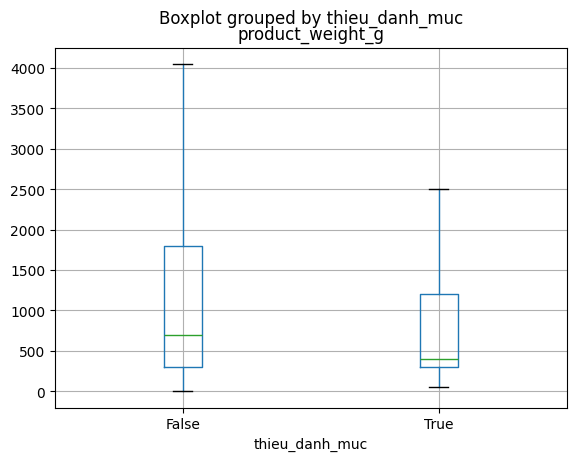

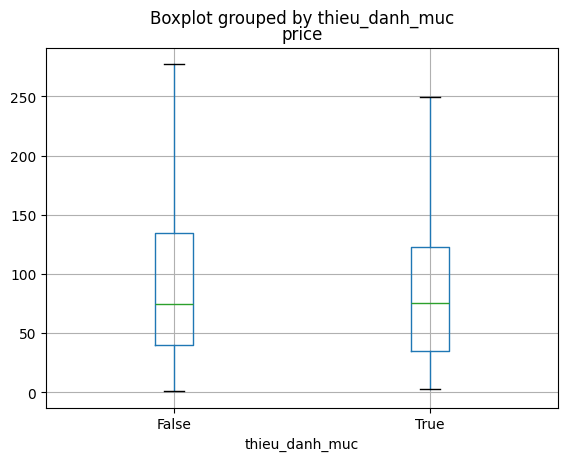

In [134]:
d = df.assign(thieu_danh_muc=mask)
d.boxplot(column='product_weight_g', by='thieu_danh_muc', showfliers=False)
plt.show()
d.boxplot(column='price', by='thieu_danh_muc', showfliers=False)
plt.show()

In thống kê mô tả cân nặng và giá cho nhóm còn danh mục (False) và nhóm thiếu danh mục (True).

In [135]:
print(df.groupby(mask)[['product_weight_g', 'price']].describe().T.round(1))

product_category_name      False    True 
product_weight_g count  110498.0   1579.0
                 mean     2098.4   1656.8
                 std      3749.9   3501.0
                 min         0.0     50.0
                 25%       300.0    300.0
                 50%       700.0    400.0
                 75%      1800.0   1200.0
                 max     40425.0  30000.0
price            count  110498.0   1579.0
                 mean      120.8    113.0
                 std       183.5    199.1
                 min         0.8      3.0
                 25%        39.9     35.0
                 50%        75.0     75.0
                 75%       135.0    123.0
                 max      6735.0   3980.0


**Kết luận:** nhóm thiếu danh mục nhẹ hơn rõ rệt về cân nặng nhưng gần như trùng về giá, nên việc thiếu danh mục không ngẫu nhiên theo cân nặng.

| Chỉ số | Còn danh mục | Thiếu danh mục |
|---|---|---|
| Cân nặng trung vị | 700 g | 400 g |
| Giá trung vị | 75 | 75 |

**Bước 3:** quyết định.

**Lựa chọn:** giữ 1,579 dòng, gán nhãn unknown cho danh mục.

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:**

- Nhãn unknown giữ lại thông tin sản phẩm thiếu danh mục.
- Nhóm thiếu danh mục khác nhóm còn lại về cân nặng, nên loại nhóm này làm đổi phân phối cân nặng.

**Hạn chế:** nhóm unknown gộp nhiều loại sản phẩm.

In [136]:
df['product_category_name'] = df['product_category_name'].fillna('unknown')
df['product_category_name_english'] = df['product_category_name_english'].fillna('unknown')
print(df[['product_category_name', 'product_category_name_english']].isna().sum())
ghi_thay_doi('4.4', 'gan nhan unknown cho danh muc thieu', int(mask.sum()), 'Quyết định', 'Không')

product_category_name            0
product_category_name_english    0
dtype: int64
4.4      gan nhan unknown cho danh muc thieu        anh huong 1579 dong


**Kết luận:** gán nhãn unknown cho 1,579 dòng; df vẫn còn 112,077 dòng.

#### 4.5 Kiểm tra lại giá trị thiếu

**Mục đích:** kiểm tra df còn giá trị thiếu hay không sau 4.2, 4.3 và 4.4.

Đếm tổng ô thiếu của df.

In [137]:
print('tong o thieu   :', df.isnull().sum().sum())

tong o thieu   : 0


### 5. Xác định phạm vi dữ liệu

**Mục đích:** giới hạn dữ liệu ở đơn đã giao và khoảng thời gian phân tích.

#### 5.1 Chỉ giữ đơn đã giao

**Câu hỏi:** dòng thuộc đơn ở trạng thái nào được dùng để học phí vận chuyển, và freight_value của các trạng thái có khác nhau không?

Đếm dòng và tính trung vị freight_value theo order_status.

In [138]:
print(df.groupby('order_status')['freight_value'].agg(['count', 'median']).round(2).sort_values('count', ascending=False))

               count  median
order_status                
delivered     109642   16.25
shipped         1178   17.63
canceled         536   15.11
processing       356   16.50
invoiced         355   15.21
unavailable        7   20.85
approved           3   10.96


**Kết luận:** 109,642 trong 112,077 dòng (97.8%) thuộc đơn delivered; trung vị freight_value của nhóm delivered là 16.25, của các nhóm khác từ 15.11 đến 17.63 (không tính approved và unavailable vì chỉ có 3 và 7 dòng).

**Lựa chọn:** chỉ giữ các dòng có order_status = delivered.

**Loại quy tắc:** Quyết định, có xem freight_value.

**Lý do:** phí của đơn chưa giao hoặc đã hủy chưa được xác nhận là phí vận chuyển đã phát sinh; trung vị freight_value của các nhóm gần nhau nên việc loại không làm lệch biến mục tiêu.

Lọc df theo trạng thái delivered bằng step().

In [139]:
keep_delivered = df['order_status'] == 'delivered'
df = step(df, keep_delivered, '5.1', 'chi giu order_status = delivered', 'Quyết định', 'Có')

5.1      chi giu order_status = delivered            112077 ->  109642 (loai 2435)


**Kết luận:** loại 2,435 dòng; df còn 109,642 dòng, đều thuộc đơn delivered.

#### 5.2 Giới hạn khoảng thời gian

**Câu hỏi:** số dòng theo tháng mua có khoảng thời gian nào bất thường không?

**Bước 1:** chuyển kiểu ngày giờ và vẽ biểu đồ cột số dòng theo tháng mua.

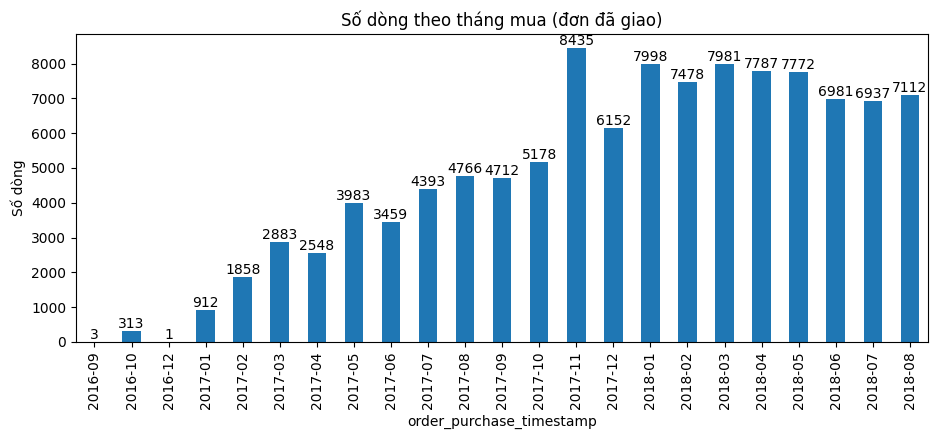

In [140]:
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
ax = df['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index().plot(kind='bar', figsize=(11, 4))
ax.bar_label(ax.containers[0])
plt.ylabel('Số dòng')
plt.title('Số dòng theo tháng mua (đơn đã giao)')
plt.show()

**Kết luận:** 2016 chỉ có 3 tháng rời rạc (3, 313 và 1 dòng, thiếu 2016-11); từ 2017-01 đến 2018-08 tháng nào cũng có dữ liệu.

**Bước 2:** quyết định.

**Lựa chọn:** giữ các đơn mua từ 01/01/2017; dữ liệu đã kết thúc ở 2018-08.

**Loại quy tắc:** Quyết định, không xem freight_value.

**Lý do:**

- Năm 2016 chỉ có 3 tháng rời rạc với 317 dòng, thiếu 2016-11 .
- Từ 2017-01 đến 2018-08, tháng nào cũng có dữ liệu .


Lọc df từ 01/2017 bằng step().

In [141]:
keep_time = (df['order_purchase_timestamp'] >= '2017-01-01') & (df['order_purchase_timestamp'] < '2018-09-01')
df = step(df, keep_time, '5.2', 'thoi gian 01/2017 den 08/2018', 'Quyết định', 'Không')

5.2      thoi gian 01/2017 den 08/2018               109642 ->  109325 (loai 317)


**Kết luận:** loại 317 dòng, tất cả thuộc năm 2016; df còn 109,325 dòng.

### 6. Xử lý giá trị sai miền

**Nguyên nhân:** Phần 2 phát hiện cân nặng bằng 0 ở bảng products (2.4); sau khi ghép, các sản phẩm này nằm trong một số dòng của df.

**Lựa chọn:** loại các dòng có product_weight_g bằng 0.

**Loại quy tắc:** Bắt buộc, không xem freight_value.

**Lý do:** cân nặng 0 g không phải giá trị hợp lệ của một sản phẩm cần vận chuyển (2.4 của Phần 2).

Loại các dòng có cân nặng bằng 0 bằng step().

In [142]:
df = step(df, df['product_weight_g'] > 0, '6', 'loai can nang bang 0', 'Bắt buộc', 'Không')

6        loai can nang bang 0                        109325 ->  109317 (loai 8)


**Kết luận:** loại 8 dòng; df còn 109,317 dòng.

### 7. Kiểm tra biến mục tiêu freight_value

**Mục đích:** kiểm tra riêng chất lượng của freight_value

#### 7.1 Phân phối

**Câu hỏi:** freight_value phân bố thế nào và có giá trị nào nằm ở biên của miền hợp lệ không?

Vẽ histogram của freight_value từ 0 đến 100 kèm vạch trung vị và in các số mô tả.

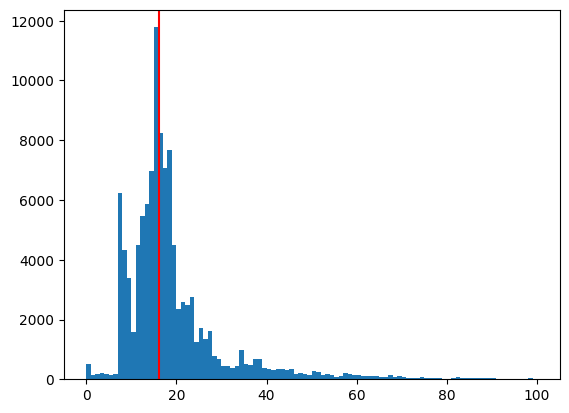

count    109317.000000
mean         19.942423
std          15.717757
min           0.000000
25%          13.070000
50%          16.250000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64


In [143]:
f = df['freight_value']
plt.hist(f, bins=100, range=(0, 100))
plt.axvline(f.median(), color='red')
plt.show()
print(f.describe())

**Kết luận:**

- freight_value tập trung quanh trung vị 16.25.
- Phân phối lệch phải với đuôi dài, giá trị lớn nhất là 409.68.
- 380 dòng có freight_value = 0.

#### 7.2 Kiểm tra freight_value = 0

**Câu hỏi:** vì sao có 380 dòng freight_value = 0?

**Giả thuyết:** phí bằng 0 vì người bán và khách ở gần nhau.

**Cách làm:** so khoảng cách trung bình và trung vị giữa người bán và khách của nhóm freight_value = 0 với nhóm còn lại.

**Lưu ý:** khoảng cách tính bằng hàm haversine_km() khai báo ở 1.1, giữa tọa độ người bán và tọa độ khách.

Tính khoảng cách của hai nhóm.

In [144]:
kc = haversine_km(df['s_lat'], df['s_lng'], df['c_lat'], df['c_lng'])
zero = df['freight_value'] == 0
print(kc.groupby(zero).agg(['mean', 'median']).round(1))

                mean  median
freight_value               
False          595.5   431.3
True           675.2   505.6


**Kết luận:** giả thuyết bị bác bỏ vì nhóm freight_value = 0 không ở gần hơn nhóm còn lại.

| Nhóm | Khoảng cách trung bình | Khoảng cách trung vị |
|---|---|---|
| freight_value = 0 | 675.2 km | 505.6 km |
| freight_value > 0 | 595.5 km | 431.3 km |

#### 7.3 Quyết định với freight_value = 0

**Lựa chọn:** loại 380 dòng freight_value = 0.

**Loại quy tắc:** Quyết định, có xem freight_value.

**Lý do:**

- Giá trị 0 không được giải thích bằng khoảng cách (7.2).
- Dữ liệu không có cột nào cho biết lý do phí bằng 0, nên giữ các dòng này buộc mô hình học một mức phí mà các đặc trưng hiện có không giải thích được.

**Hạn chế:** chưa xác định freight bằng 0 là miễn phí vận chuyển, mã giảm giá hay lỗi ghi nhận; mô hình không dự đoán được trường hợp miễn phí vận chuyển.

Loại các dòng freight_value = 0 bằng step() và so trung bình, trung vị của freight_value trước và sau khi loại.

In [145]:
truoc = df['freight_value']
df = step(df, df['freight_value'] > 0, '7.3', 'loai freight_value = 0', 'Quyết định', 'Có')

7.3      loai freight_value = 0                      109317 ->  108937 (loai 380)




### 8. Audit trail

**Mục đích:** tổng hợp các bước loại dòng và các bước sửa giá trị, kiểm tra tổng số dòng loại khớp với số dòng cuối.

Tạo hai bảng nhật ký, kiểm tra tổng số dòng loại và cộng theo loại quy tắc.

In [146]:
audit = pd.DataFrame(audit_rows)
thay_doi = pd.DataFrame(change_rows)
print(audit)
print('khop so dong cuoi:', audit['truoc'].iloc[0] - audit['so_dong_loai'].sum() == len(df))
print()
print(audit.groupby('loai_quy_tac')['so_dong_loai'].sum())
print()
print(thay_doi)

   muc                            quy_tac loai_quy_tac co_xem_freight   truoc     sau  so_dong_loai
0  4.2                  loai thieu toa do   Quyết định          Không  112650  112095           555
1  4.3  loai thieu can nang va kich thuoc   Quyết định          Không  112095  112077            18
2  5.1   chi giu order_status = delivered   Quyết định             Có  112077  109642          2435
3  5.2      thoi gian 01/2017 den 08/2018   Quyết định          Không  109642  109325           317
4    6               loai can nang bang 0     Bắt buộc          Không  109325  109317             8
5  7.3             loai freight_value = 0   Quyết định             Có  109317  108937           380
khop so dong cuoi: True

loai_quy_tac
Bắt buộc         8
Quyết định    3705
Name: so_dong_loai, dtype: int64

   muc                              quy_tac loai_quy_tac co_xem_freight  so_dong_anh_huong
0  4.4  gan nhan unknown cho danh muc thieu   Quyết định          Không               1579


**Kết luận:** 6 bước loại tổng cộng 3,713 dòng (3.30%), từ 112,650 xuống 108,937; tổng khớp số dòng cuối.

| Mục | Quy tắc | Loại quy tắc | Có xem freight_value | Số dòng loại |
|---|---|---|---|---|
| 4.2 | Thiếu tọa độ | Quyết định | Không | 555 |
| 4.3 | Thiếu cân nặng và kích thước | Quyết định | Không | 18 |
| 5.1 | Chỉ giữ đơn delivered | Quyết định | Có | 2,435 |
| 5.2 | Thời gian 01/2017 đến 08/2018 | Quyết định | Không | 317 |
| 6 | Giá trị sai miền | Bắt buộc | Không | 8 |
| 7.3 | freight_value = 0 | Quyết định | Có | 380 |

| Bước sửa giá trị | Loại quy tắc | Số dòng ảnh hưởng |
|---|---|---|
| 4.4 Gắn nhãn unknown cho danh mục thiếu | Quyết định | 1,579 |

### 9. Chuyển đổi dữ liệu

**Mục đích:** từ df đã làm sạch ở mục 8 (108,937 dòng, 24 cột), tạo biến thời gian và đặc trưng, chốt grain và schema, rồi kiểm tra ngoại lai trên các biến đã chốt.

#### 9.1 Biến thời gian

Tạo t_days (số ngày kể từ 01/01/2017) và month (YYYY-MM) từ order_purchase_timestamp, rồi in khoảng giá trị.

In [147]:
T0 = pd.to_datetime('2017-01-01')
df['t_days'] = (df['order_purchase_timestamp'] - T0).dt.days
df['month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)

print('t_days :', df['t_days'].min(), '->', df['t_days'].max())
print('month  :', df['month'].min(), '->', df['month'].max(), '|', df['month'].nunique(), 'thang')

t_days : 4 -> 605
month  : 2017-01 -> 2018-08 | 20 thang


**Kết luận:** t_days từ 4 đến 605; month có 20 giá trị, từ 2017-01 đến 2018-08.

#### 9.2 Bổ sung số sản phẩm của đơn

Thêm order_n_items, số sản phẩm của mỗi đơn, đếm trên bảng items gốc.

In [148]:
df['order_n_items'] = df['order_id'].map(items.groupby('order_id').size())
print('lon nhat:', df['order_n_items'].max())
print(df.shape)

lon nhat: 21
(108937, 27)


#### 9.3 Ý nghĩa của freight_value ở đơn nhiều sản phẩm

**Câu hỏi:** ở đơn nhiều sản phẩm, freight_value của mỗi dòng là phí riêng của sản phẩm hay một phần phí của cả đơn bị chia ra?

So freight_value của từng dòng với trung vị phí của cùng (product_id, seller_id, customer_state) ở các đơn một sản phẩm. Nếu phí bị chia thì chênh lệch lệch âm.

In [149]:
khoa = ['product_id', 'seller_id', 'customer_state']
phi = df[df['order_n_items'] == 1].groupby(khoa)['freight_value'].median().rename('phi_mot_mon')
so_sanh = df[df['order_n_items'] > 1].join(phi, on=khoa).dropna(subset=['phi_mot_mon'])
chenh = so_sanh['freight_value'] - so_sanh['phi_mot_mon']

print('dong don nhieu san pham:', (df['order_n_items'] > 1).sum(), '| co muc doi chieu:', len(so_sanh))
print(chenh.describe().round(2))
print('ty le lech trong 10%:', (chenh.abs() <= 0.1 * so_sanh['phi_mot_mon']).mean().round(3))

dong don nhieu san pham: 23081 | co muc doi chieu: 10077
count    10077.00
mean        -0.01
std          7.74
min        -89.04
25%         -1.05
50%          0.00
75%          0.95
max        182.60
dtype: float64
ty le lech trong 10%: 0.565


**Kết luận:** chênh lệch có trung vị 0.00 và trung bình -0.01, không có dấu hiệu phí của cả đơn bị chia.

**Lựa chọn:** giữ nguyên freight_value ở cấp sản phẩm.

**Loại quy tắc:** Quyết định, có xem freight_value.

**Lý do:** gộp theo đơn làm mất cân nặng, kích thước và danh mục của từng sản phẩm.

**Hạn chế:** chỉ 10,077 trong 23,081 dòng có mức đối chiếu; 43.5% dòng lệch hơn 10%, chưa rõ nguyên nhân.



#### 9.4 Chốt grain

Đếm dòng trùng theo (order_id, order_item_id), cặp xác định một sản phẩm trong một đơn.

In [150]:
print('trung theo grain:', df.duplicated(['order_id', 'order_item_id']).sum())

trung theo grain: 0


**Kết luận:** không có dòng trùng, nên (order_id, order_item_id) xác định duy nhất từng dòng.



#### 9.5 Tạo đặc trưng

- distance_km: khoảng cách đường chim bay giữa người bán và khách, tính bằng haversine_km() từ tọa độ đại diện của hai mã bưu chính.
- volume_cm3: tích chiều dài, chiều cao và chiều rộng; ba cạnh thô vẫn được giữ vì hai sản phẩm cùng thể tích có thể khác hình dạng.
- same_state: bằng 1 nếu seller_state trùng customer_state, ngược lại bằng 0.

**Công thức haversine** [5] tính khoảng cách giữa hai điểm trên mặt cầu bán kính 6,371 km:

- Đổi vĩ độ φ và kinh độ λ từ độ sang radian bằng np.radians.
- a = sin²((φ2 − φ1) / 2) + cos φ1 · cos φ2 · sin²((λ2 − λ1) / 2); a nằm trong khoảng 0 đến 1, a = 0 khi hai điểm trùng nhau, a = 1 khi hai điểm ở hai đầu đối xứng của mặt cầu.
- c = 2 · arcsin(√a), d = 6371 · c (km). Kết quả là đường thẳng trên mặt cầu, không phải quãng đường vận chuyển thực.

Tính ba đặc trưng và in thống kê mô tả.

In [151]:
df['distance_km'] = haversine_km(df['s_lat'], df['s_lng'], df['c_lat'], df['c_lng'])
df['volume_cm3'] = df['product_length_cm'] * df['product_height_cm'] * df['product_width_cm']
df['same_state'] = (df['seller_state'] == df['customer_state']).astype(int)

print(df[['distance_km', 'volume_cm3', 'same_state']].describe().round(2))
print(df.shape)

       distance_km  volume_cm3  same_state
count    108937.00   108937.00   108937.00
mean        595.47    15213.89        0.36
std         587.43    23301.71        0.48
min           0.00      168.00        0.00
25%         182.15     2850.00        0.00
50%         431.31     6468.00        0.00
75%         790.87    18375.00        1.00
max        3398.49   296208.00        1.00
(108937, 30)


**Kết luận:** ba đặc trưng đầy đủ cho 108,937 dòng; distance_km từ 0 đến 3,398.49 km (trung vị 431.31), volume_cm3 từ 168 đến 296,208 cm³ (trung vị 6,468), same_state bằng 1 ở 36.4% dòng; df có 30 cột.

#### 9.6 Đổi tên cột và chốt schema

Đổi tên 7 cột sang tên ngắn; bỏ order_status (chỉ còn delivered), shipping_limit_date (không dùng làm đặc trưng) và product_category_name (trùng với category).

In [152]:
df = df.rename(columns={
    'product_weight_g': 'weight_g',
    'product_length_cm': 'length_cm',
    'product_height_cm': 'height_cm',
    'product_width_cm': 'width_cm',
    'product_category_name_english': 'category',
    'seller_zip_code_prefix': 's_zip',
    'customer_zip_code_prefix': 'c_zip',
})
df = df.drop(columns=['order_status', 'shipping_limit_date', 'product_category_name'])
print(df.shape)

(108937, 27)


**Kết luận:** schema cuối gồm 108,937 dòng và 27 cột.

#### 9.7 Từ điển dữ liệu

In kiểu dữ liệu của từng cột để đối chiếu với từ điển.

In [153]:
print(df.dtypes)

order_id                            object
order_item_id                        int64
product_id                          object
seller_id                           object
price                              float64
freight_value                      float64
customer_id                         object
order_purchase_timestamp    datetime64[ns]
weight_g                           float64
length_cm                          float64
height_cm                          float64
width_cm                           float64
category                            object
c_zip                                int64
customer_state                      object
s_zip                                int64
seller_state                        object
c_lat                              float64
c_lng                              float64
s_lat                              float64
s_lng                              float64
t_days                               int64
month                               object
order_n_ite

**Kết luận:** 27 cột của từ điển khớp với schema ở 9.6.

| Cột | Kiểu | Nguồn | Ý nghĩa | Vai trò |
|---|---|---|---|---|
| order_id, order_item_id | chuỗi, số nguyên | items | Mã đơn hàng; số thứ tự sản phẩm trong đơn | Khóa (grain) |
| product_id, seller_id, customer_id | chuỗi | items, orders | Mã sản phẩm, người bán, khách hàng | Định danh |
| price | số thực | items | Giá bán của sản phẩm (BRL) | Đặc trưng |
| freight_value | số thực | items | Phí vận chuyển của sản phẩm trong đơn (BRL) | Biến mục tiêu |
| order_purchase_timestamp | ngày giờ | orders | Thời điểm khách đặt hàng | Thời gian |
| weight_g, length_cm, height_cm, width_cm | số thực | products | Cân nặng (gam); chiều dài, chiều cao, chiều rộng (cm) | Đặc trưng |
| category | chuỗi | cat_map | Danh mục tiếng Anh; unknown nếu thiếu danh mục (4.4) | Đặc trưng |
| c_zip, s_zip | số nguyên | customers, sellers | Mã bưu chính của khách; của người bán | Khóa ghép, không làm đặc trưng |
| customer_state, seller_state | chuỗi | customers, sellers | Bang của khách; của người bán | Đặc trưng |
| c_lat, c_lng, s_lat, s_lng | số thực | geo | Tọa độ khách và người bán, trung vị theo mã bưu chính (2.1) | Vị trí |
| t_days, month | số nguyên, chuỗi | 9.1 | Số ngày từ 01/01/2017 đến ngày mua; tháng mua YYYY-MM | Thời gian |
| order_n_items | số nguyên | 9.2 | Số sản phẩm của đơn | Đặc trưng |
| distance_km, volume_cm3, same_state | số thực, số thực, 0/1 | 9.5 | Khoảng cách đường chim bay người bán - khách; dài × cao × rộng; 1 nếu cùng bang | Đặc trưng |



#### 9.8 Phát hiện và xử lý giá trị ngoại lai

Vẽ boxplot và đếm giá trị vượt rào trên theo IQR cho price, distance_km, volume_cm3 và freight_value.

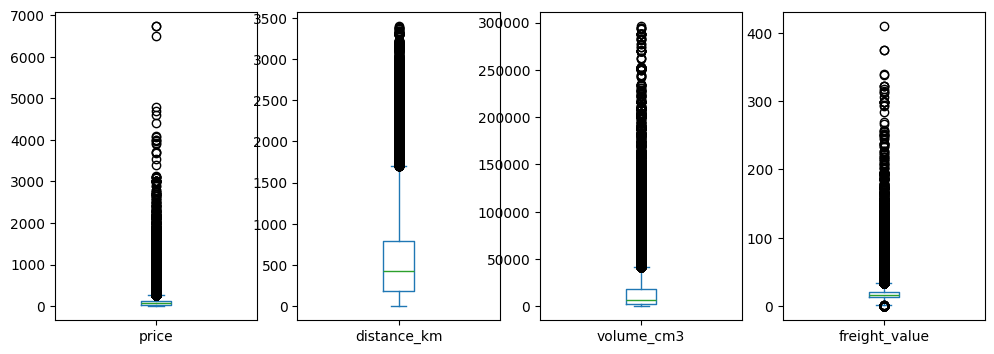

               so_dong  ty_le_%
price             8069     7.41
distance_km       8304     7.62
volume_cm3        9676     8.88
freight_value    11216    10.30


In [154]:
cot = ['price', 'distance_km', 'volume_cm3', 'freight_value']
df[cot].plot(kind='box', subplots=True, layout=(1, 4), figsize=(12, 4))
plt.show()

q1, q3 = df[cot].quantile(0.25), df[cot].quantile(0.75)
vuot = df[cot] > q3 + 1.5 * (q3 - q1)
print(pd.DataFrame({'so_dong': vuot.sum(), 'ty_le_%': vuot.mean() * 100}).round(2))

Để xác định giá trị vượt rào là lỗi hay là đơn hàng thực, so trung vị freight_value giữa nhóm vượt rào trên và nhóm còn lại của từng đặc trưng; với freight_value, so trung vị distance_km và weight_g.

In [155]:
for c, x in [('price', 'freight_value'), ('distance_km', 'freight_value'), ('volume_cm3', 'freight_value'),
             ('freight_value', 'distance_km'), ('freight_value', 'weight_g')]:
    print(f'{c:<14}{x:<14}', df.groupby(vuot[c])[x].median().round(2).to_dict())

price         freight_value  {False: 16.05, True: 24.83}
distance_km   freight_value  {False: 15.81, True: 29.34}
volume_cm3    freight_value  {False: 15.9, True: 30.38}
freight_value distance_km    {False: 404.1, True: 916.16}
freight_value weight_g       {False: 600.0, True: 5950.0}


**Nhận xét và lý do xử lý giá trị ngoại lai (mục 9.8):**

**Phát hiện:**
- Số giá trị vượt rào trên: price 8,069 (7.41%); distance_km 8,304 (7.62%); volume_cm3 9,676 (8.88%); freight_value 11,216 (10.30%).

**Cách xử lý:** giữ nguyên, không loại (trimming) và không giới hạn giá trị (capping); df vẫn 108,937 dòng.

**Lý do:**
- Nhóm vượt rào của price, distance_km và volume_cm3 đều có trung vị freight_value cao hơn nhóm còn lại (24.83 so với 16.05; 29.34 so với 15.81; 30.38 so với 15.9).
- Nhóm freight_value vượt rào có trung vị distance_km cao hơn (916.16 so với 404.1 km) và trung vị weight_g cao hơn (5,950 so với 600 g), phù hợp với hàng nặng, đi xa.
- freight_value là biến mục tiêu: loại hoặc giới hạn làm đổi đại lượng cần dự đoán, và loại thì mất 11,216 dòng.
- Ngưỡng IQR phụ thuộc phân phối nên nếu cần giới hạn thì tính trên tập huấn luyện ở giai đoạn mô hình hóa (1.3.1).


### 10. Tự đánh giá và kết luận

#### 10.1 So sánh trước và sau làm sạch

In các chỉ số của bảng cuối kèm giá trị ngay sau khi ghép hoặc ở bảng nguồn.

In [156]:
print('so dong           :', len(items), '->', len(df))
print('so cot            :', len(miss), '->', df.shape[1])
print('o thieu           :', miss.sum(), '->', df.isnull().sum().sum())
print('dong trung grain  :', items.duplicated(['order_id', 'order_item_id']).sum())
print('kieu ngay mua     :', orders['order_purchase_timestamp'].dtype, '->', df['order_purchase_timestamp'].dtype)
print('weight = 0        :', (products['product_weight_g'] == 0).sum(), 'san pham ->', (df['weight_g'] == 0).sum(), 'dong')
print('freight_value = 0 :', (items['freight_value'] == 0).sum(), 'dong ->', (df['freight_value'] == 0).sum(), 'dong')

so dong           : 112650 -> 108937
so cot            : 24 -> 27
o thieu           : 4390 -> 0
dong trung grain  : 0
kieu ngay mua     : object -> datetime64[ns]
weight = 0        : 4 san pham -> 0 dong
freight_value = 0 : 383 dong -> 0 dong


**Đối chiếu các phát hiện ở 1.2 với kết quả xử lý:**

| STT | Vấn đề ở 1.2 | Cách xử lý | Mục |
|---|---|---|---|
| 1 | 8 cột ngày ở kiểu chữ | Chỉ order_purchase_timestamp được nạp và chuyển sang kiểu ngày; các cột ngày còn lại không dùng | 5.2 |
| 2 | order_approved_at thiếu 160 dòng | Không nạp vào bảng ghép | 3 |
| 3 | order_delivered_carrier_date thiếu 1,783 dòng | Không nạp vào bảng ghép | 3 |
| 4 | order_delivered_customer_date thiếu 2,965 dòng | Không nạp vào bảng ghép | 3 |
| 5 | products: danh mục và ba trường mô tả thiếu 610 ô mỗi trường | Gán nhãn unknown cho danh mục thiếu (1,579 dòng); ba trường mô tả không nạp | 4.4 |
| 6 | products: cân nặng và ba kích thước thiếu 2 ô mỗi trường | Loại 18 dòng thiếu | 4.3 |
| 7 | geo trùng hoàn toàn 261,831 dòng | Giữ nguyên dòng trùng; mỗi mã bưu chính một dòng nhờ gộp theo trung vị | 2.1 |
| 8 | freight_value bằng 0 (383 dòng ở bảng items) | Loại 380 dòng còn lại tại thời điểm xử lý | 7.3 |
| 9 | product_weight_g bằng 0 (4 sản phẩm) | Loại 8 dòng có cân nặng bằng 0 | 6 |
| 10 | Tọa độ ngoài khung Brazil | Loại 31 điểm ngoài khung trước khi tính tọa độ đại diện | 2.1 |
| 11 | geo: 1,000,163 dòng cho 19,015 mã bưu chính | Gộp theo trung vị, còn 19,011 mã, mỗi mã một dòng | 2.1 |
| 12 | Danh mục không có bản dịch (13 sản phẩm) | Bổ sung bản dịch thủ công cho 2 danh mục | 2.3 |
| 13 | Khách hàng không có tọa độ (278 dòng) | Loại 555 dòng thiếu tọa độ ở ít nhất một phía | 4.2 |
| 14 | Người bán không có tọa độ (7 người bán) | Loại 555 dòng thiếu tọa độ ở ít nhất một phía | 4.2 |
| 15 | Độ phủ thời gian không đồng đều | Loại 317 dòng năm 2016 | 5.2 |
| 16 | Giá trị vượt rào IQR | Đo lại trên bảng cuối, giữ nguyên | 9.8 |
| 17 | Nguy cơ rò rỉ dữ liệu ở payments | Không nạp vào Phần 3 | 1.2 |



#### 10.2 Hạn chế của dữ liệu cuối

Đo bốn số trên bảng cuối: dòng có mã chứa điểm cách tọa độ đại diện trên 10 km, dòng cùng mã bưu chính, dòng category unknown, và dòng có mã đổi tọa độ trên 10 km nếu bỏ dòng trùng của geo.

In [157]:
print('dong cung ma buu chinh :', (df['s_zip'] == df['c_zip']).sum())
print('dong category = unknown:', (df['category'] == 'unknown').sum())

dong cung ma buu chinh : 26
dong category = unknown: 1510


#### 10.2 Hạn chế không khắc phục được của dữ liệu cuối

**Kết luận:** dữ liệu cuối còn 3 hạn chế không khắc phục được bằng dữ liệu hiện có.

| Hạn chế | Số liệu | Lý do không khắc phục được | Mục |
|---|---|---|---|
| Thiếu thông tin vận chuyển | distance_km chỉ là đường chim bay | Dữ liệu không có hãng vận chuyển, phương thức giao và quãng đường thực | 9.5 |
| Nhãn freight_value của đơn nhiều sản phẩm không xác định hết | 23,081 dòng (21.2%); 10,077 dòng có mức đối chiếu, trong đó 43.5% lệch trên 10% | Dữ liệu không ghi cách phí được tính cho đơn | 9.3 |
| Chỉ có giai đoạn 01/2017 đến 08/2018 | Đơn delivered kết thúc ở 08/2018; năm 2016 chỉ 317 dòng rời rạc | Dữ liệu không có thời gian khác | 5.2 |

#### 10.3 Đầu ra

Ghi bảng cuối ra olist_freight_clean.csv trên Drive rồi đọc lại để so với df.

In [158]:
import os

output_dir = raw + 'output/'
os.makedirs(output_dir, exist_ok=True)
df.to_csv(output_dir + 'olist_freight_clean.csv', index=False, encoding='utf-8-sig')

df_doc = pd.read_csv(output_dir + 'olist_freight_clean.csv')
print('so dong df / tep        :', len(df), '/', len(df_doc))
print('tong freight df / tep   :', round(df['freight_value'].sum(), 2), '/', round(df_doc['freight_value'].sum(), 2))
print('o thieu cua tep         :', df_doc.isnull().sum().sum())
print('dong trung grain cua tep:', df_doc.duplicated(['order_id', 'order_item_id']).sum())

so dong df / tep        : 108937 / 108937
tong freight df / tep   : 2180045.81 / 2180045.81
o thieu cua tep         : 0
dong trung grain cua tep: 0


**Kết luận:** tệp olist_freight_clean.csv khớp với df: 108,937 dòng, tổng freight_value 2,180,045.81, không ô thiếu, không dòng trùng grain.

**Lưu ý:** tệp là dữ liệu dẫn xuất từ bộ dữ liệu Olist [3], phát hành theo giấy phép CC BY-NC-SA 4.0 [4].

#### 10.4 Kết luận

Bảng cuối gồm 108,937 dòng, 27 cột, mỗi dòng là một sản phẩm trong một đơn đã giao từ 01/2017 đến 08/2018, không thiếu, không trùng grain, không sai miền (price và freight_value không âm, kích thước dương, mã bang hợp lệ ở 2.4 của Phần 2; cân nặng bằng 0 đã xử lý ở mục 6).

- Loại 3,713 dòng (3.30%): 8 dòng Bắt buộc và 3,705 dòng Quyết định (mục 8).
- Bốn quyết định có xem freight_value: giữ đơn delivered (5.1), loại 380 dòng freight_value = 0 (7.3), giữ freight_value ở cấp sản phẩm (9.3) và giữ giá trị vượt rào IQR (9.8).
- Dòng thiếu tọa độ bị loại thay vì điền theo bang (lệch 79.6 km so với 1.27 km, 4.2).

**Việc chuyển sang bước sau:**

- So mô hình khi huấn luyện có và không có các dòng freight_value = 0, và có và không có đơn khác delivered (5.1), cùng đánh giá trên một tập kiểm tra.
- Báo cáo sai số riêng cho đơn nhiều sản phẩm (9.3) và category = unknown; thử biến đổi log cho các biến lệch phải (9.8).
- Chia train/test theo thời gian, mã hóa và chuẩn hóa chỉ khớp trên tập huấn luyện để tránh rò rỉ dữ liệu [1], so mô hình đối chứng (trung vị freight_value của tập huấn luyện) với các mô hình hồi quy bằng MAE, RMSE và R².

#### 10.5 Nguồn tham khảo

[1] S. Kaufman, S. Rosset, C. Perlich, O. Stitelman, Leakage in data mining: formulation, detection, and avoidance, ACM Transactions on Knowledge Discovery from Data 6(4), 2012. DOI: 10.1145/2382577.2382579.

[2] NIST, Security and Privacy Controls for Information Systems and Organizations, SP 800-53 Rev. 5, 2020. DOI: 10.6028/NIST.SP.800-53r5.

[3] Olist, Brazilian E-Commerce Public Dataset by Olist, Kaggle: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce.

[4] Creative Commons, Attribution-NonCommercial-ShareAlike 4.0 International: https://creativecommons.org/licenses/by-nc-sa/4.0/.

[5] Haversine formula, Wikipedia: https://en.wikipedia.org/wiki/Haversine_formula.